# Data Preprocessing for Mold Risk Detection

This notebook performs data preprocessing on the environmental sensor dataset to prepare it for visualization and analysis. We'll focus on:

1. Loading and exploring the dataset
2. Cleaning the data (handling missing values, duplicates)
3. Feature engineering and transformations
4. Creating visualizations including correlation heatmaps and boxplots
5. Preparing data for modeling

## Libraries and Setup

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import os

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Set plot style and size
plt.style.use('seaborn-whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

## 1. Data Loading and Exploration

Let's load the dataset and explore its structure.

In [8]:
file_path = '../Dataset Creation/building_mold_risk_5min_1year(2).csv'
data = pd.read_csv(file_path)

In [10]:
print("Data types:")
print(data.dtypes)
print("\nSummary statistics:")
data.describe()

Data types:
Date                object
Timestamp           object
Humidity           float64
Temperature        float64
Light_Intensity    float64
Pressure           float64
Mold_Risk           object
dtype: object

Summary statistics:


,Humidity,Temperature,Light_Intensity,Pressure
count,210528.000000,210528.000000,210528.000000,210528.000000
mean,60.006245,21.998080,283.865820,1012.992201
std,13.341343,6.816912,289.886259,7.644548
min,30.000000,5.000000,0.000000,993.039773
25%,50.095973,17.115666,10.352908,1006.435216
50%,60.003252,21.962688,237.478223,1013.010985
75%,69.899009,26.909583,542.969648,1019.542883
max,98.975030,40.000000,974.909579,1033.146994


In [11]:
print("Missing values count:")
data.isnull().sum()

Missing values count:


Date               0
Timestamp          0
Humidity           0
Temperature        0
Light_Intensity    0
Pressure           0
Mold_Risk          0
dtype: int64

In [12]:
print("Mold Risk Distribution:")
risk_distribution = data['Mold_Risk'].value_counts()
print(risk_distribution)

Mold Risk Distribution:
Mold_Risk
Low         149788
Moderate     54414
High          6326
Name: count, dtype: int64


## 2. Data Cleaning and Preparation

Let's prepare the data by:
- Converting date/time columns to appropriate formats
- Checking for and handling outliers
- Ensuring all features are in the right format for analysis

In [15]:
# Convert date and timestamp columns to datetime
data['Date'] = pd.to_datetime(data['Date'])
data['Timestamp'] = pd.to_datetime(data['Timestamp'])

# Extract useful time features
data['Hour'] = data['Timestamp'].dt.hour
data['Day'] = data['Timestamp'].dt.day
data['Month'] = data['Timestamp'].dt.month
data['DayOfWeek'] = data['Timestamp'].dt.dayofweek
data.head()

,Date,Timestamp,Humidity,Temperature,Light_Intensity,Pressure,Mold_Risk,Hour,Day,Month,DayOfWeek
0,2023-01-01,2023-01-01 00:00:00,52.245057,14.570697,6.817015,1007.767363,Low,0,1,1,6
1,2023-01-01,2023-01-01 00:05:00,49.707523,19.608253,15.293582,1011.349784,Low,0,1,1,6
2,2023-01-01,2023-01-01 00:10:00,52.858472,16.899816,13.860965,1008.260568,Low,0,1,1,6
3,2023-01-01,2023-01-01 00:15:00,56.371731,16.479008,10.968901,1010.276541,Low,0,1,1,6
4,2023-01-01,2023-01-01 00:20:00,49.359640,14.269151,9.284453,1010.289639,Low,0,1,1,6


In [17]:
# Check for duplicates
duplicate_count = data.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# Remove duplicates if any
if duplicate_count > 0:
    data = data.drop_duplicates()
    print(f"Duplicates removed. New shape: {data.shape}")


Number of duplicate rows: 0


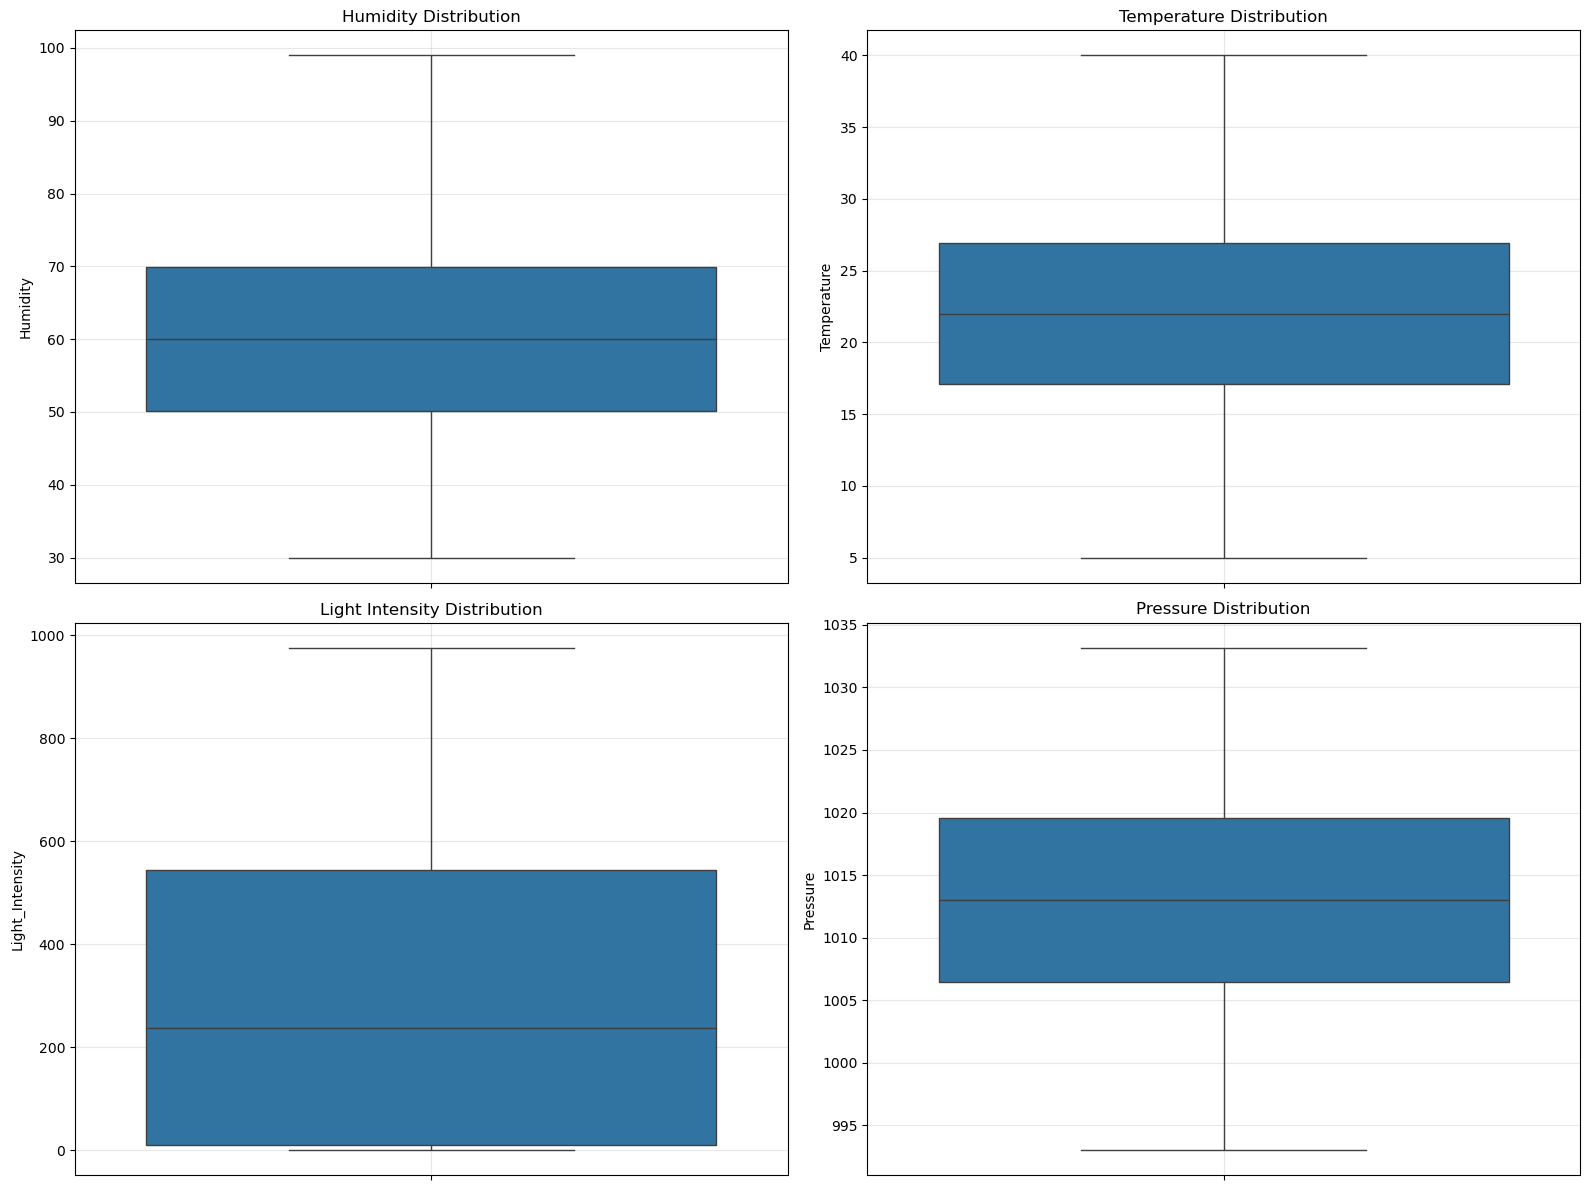

In [18]:
# Detect outliers using boxplots for each sensor reading
plt.figure(figsize=(16, 12))

plt.subplot(2, 2, 1)
sns.boxplot(y='Humidity', data=data)
plt.title('Humidity Distribution')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
sns.boxplot(y='Temperature', data=data)
plt.title('Temperature Distribution')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 3)
sns.boxplot(y='Light_Intensity', data=data)
plt.title('Light Intensity Distribution')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 4)
sns.boxplot(y='Pressure', data=data)
plt.title('Pressure Distribution')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Feature Engineering and Data Transformation

Let's create some useful derived features and transform the data for better analysis.

In [19]:
# Create binary flag for day/night (assuming 6 AM to 6 PM is day)
data['IsDay'] = ((data['Hour'] >= 6) & (data['Hour'] < 18)).astype(int)

# Create a numerical encoding for Mold_Risk for correlation analysis
risk_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}
data['Mold_Risk_Numeric'] = data['Mold_Risk'].map(risk_mapping)

In [ ]:
# Calculate hour-of-day patterns
hourly_patterns = data.groupby('Hour').agg({
    'Humidity': 'mean',
    'Temperature': 'mean',
    'Light_Intensity': 'mean',
    'Pressure': 'mean',
    'Mold_Risk_Numeric': 'mean'
}).reset_index()

# Plot hourly patterns
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(hourly_patterns['Hour'], hourly_patterns['Humidity'], marker='o', linestyle='-')
plt.title('Average Humidity by Hour')
plt.grid(True, alpha=0.3)

plt.subplot(3, 2, 2)
plt.plot(hourly_patterns['Hour'], hourly_patterns['Temperature'], marker='o', linestyle='-', color='orange')
plt.title('Average Temperature by Hour')
plt.grid(True, alpha=0.3)

plt.subplot(3, 2, 3)
plt.plot(hourly_patterns['Hour'], hourly_patterns['Light_Intensity'], marker='o', linestyle='-', color='green')
plt.title('Average Light Intensity by Hour')
plt.grid(True, alpha=0.3)

plt.subplot(3, 2, 4)
plt.plot(hourly_patterns['Hour'], hourly_patterns['Pressure'], marker='o', linestyle='-', color='red')
plt.title('Average Pressure by Hour')
plt.grid(True, alpha=0.3)

plt.subplot(3, 2, 5)
plt.plot(hourly_patterns['Hour'], hourly_patterns['Mold_Risk_Numeric'], marker='o', linestyle='-', color='purple')
plt.title('Average Mold Risk by Hour')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Correlation Analysis and Visualization

Let's create correlation heatmaps to analyze relationships between variables.

In [ ]:
# Select numerical columns for correlation analysis
numerical_cols = ['Humidity', 'Temperature', 'Light_Intensity', 'Pressure', 'Hour', 'Day', 'Month', 'Mold_Risk_Numeric']
correlation_data = data[numerical_cols]

# Calculate correlation matrix
corr_matrix = correlation_data.corr()

# Visualize correlation matrix as a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Environmental Variables')
plt.tight_layout()
plt.show()

In [20]:
# Calculate daily averages for sensor readings
daily_avg = data.groupby('Date').agg({
    'Humidity': 'mean',
    'Temperature': 'mean',
    'Light_Intensity': 'mean',
    'Pressure': 'mean',
    'Mold_Risk_Numeric': 'mean'
}).reset_index()

daily_avg.head()

,Date,Humidity,Temperature,Light_Intensity,Pressure,Mold_Risk_Numeric
0,2023-01-01,60.213819,22.100438,286.758641,1013.045506,0.208333
1,2023-01-02,60.417324,22.430256,292.278053,1013.350112,0.243056
2,2023-01-03,60.941800,22.277058,291.996697,1013.687685,0.256944
3,2023-01-04,61.628263,22.245804,292.285317,1013.765548,0.246528
4,2023-01-05,61.466006,22.567021,296.328447,1013.852441,0.281250


## 5. Box Plots by Mold Risk Category

Let's create box plots to visualize how each environmental variable varies across different mold risk categories.

In [ ]:
# Create box plots for each environmental variable by Mold_Risk
plt.figure(figsize=(16, 14))

plt.subplot(2, 2, 1)
sns.boxplot(x='Mold_Risk', y='Humidity', data=data, palette='viridis')
plt.title('Humidity Distribution by Mold Risk')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
sns.boxplot(x='Mold_Risk', y='Temperature', data=data, palette='viridis')
plt.title('Temperature Distribution by Mold Risk')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 3)
sns.boxplot(x='Mold_Risk', y='Light_Intensity', data=data, palette='viridis')
plt.title('Light Intensity Distribution by Mold Risk')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 4)
sns.boxplot(x='Mold_Risk', y='Pressure', data=data, palette='viridis')
plt.title('Pressure Distribution by Mold Risk')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Advanced Visualization: Pair Plots

Let's create a pair plot to visualize relationships between variables and how they relate to mold risk.

In [ ]:
# Create a sample of the data for the pair plot (to avoid overcrowding)
# Sample 5% of the data for better visualization
data_sample = data.sample(frac=0.05, random_state=42)

# Create pair plot
sns.pairplot(data_sample, 
             vars=['Humidity', 'Temperature', 'Light_Intensity', 'Pressure'],
             hue='Mold_Risk', 
             palette='viridis',
             corner=True,
             diag_kind='kde')

plt.suptitle('Pair Plot of Environmental Variables by Mold Risk', y=1.02)
plt.show()

## 7. Prepare Data for Modeling

Let's prepare the data for machine learning by:
- Splitting into features and target
- Handling categorical variables
- Creating a final cleaned dataset

In [ ]:
# Prepare features and target
X = data[['Humidity', 'Temperature', 'Light_Intensity', 'Pressure', 'Hour', 'Day', 'Month', 'DayOfWeek', 'IsDay']]
y = data['Mold_Risk']

# Preview the prepared data
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Save the processed dataset
processed_data = pd.concat([X, y], axis=1)
processed_data.head()

In [ ]:
# Save the processed data to a new CSV file
output_dir = '../Data Preprocessing/Processed_Data'
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, 'processed_mold_risk_data.csv')
processed_data.to_csv(output_path, index=False)

print(f"Processed data saved to {output_path}")

## 8. Summary and Insights

Based on our preprocessing and analysis, we've gained several insights:

1. **Correlation Analysis**: We've identified the variables most strongly correlated with mold risk.
2. **Box Plots**: We've visualized how environmental factors differ across mold risk categories.
3. **Feature Engineering**: We've created time-based features that may help predict mold risk.
4. **Data Quality**: We've checked for and addressed any data quality issues.

The processed dataset is now ready for modeling and further analysis.